# Across-Trials Testing

This test is designed to study differences between trials within one or more experimental sessions. It’s useful for analysing how brain dynamics vary across different stimuli or task conditions.

To focus on the statistical testing, we use synthetic data generated using the Genephys toolbox by Vidaurre (2023). Genephys simulates EEG or MEG data in psychometric experiments, where a subject is repeatedly exposed to stimuli,

For this tutorial:

D: Gamma values — the decoded state probabilities from an HMM. These were computed from synthetic EEG/MEG-like data across 1421 trials (250 timepoints per trial), grouped into 10 sessions.

R: categorical labels representing the stimulus shown on each trial (e.g., animate vs inanimate objects).

In [ ]:
# Now import everything we need
import numpy as np
from pathlib import Path
from glhmm import graphics, statistics
np.random.seed(0)  # For reproducibility

``Gamma_trials``: decoded HMM state probabilities (Gamma values)
Shape (n_timepoints × n_trials, n_states) : 355,250 × 6 — where 355,250 = 250 timepoints × 1421 subjects
Each row is a timepoint; each column corresponds to one of 6 HMM states

``R_trials``: stimulus condition label for each trial (0 or 1) Shape (n_trials,): 1D array with one value for each of 1421 trials

``idx_trials_session``: session boundaries
Shape (n_sessions, 2): 2D array with 10 rows — each row defines the start and end index for a session

In [ ]:
# Load brain and behavioral data
Gamma = np.load("./data_statistical_testing/Gamma_trials.npy")
R_trials = np.load("./data_statistical_testing/R_trials.npy")
idx_trials_session = np.load("./data_statistical_testing/idx_trials_session.npy")

# Check data dimensions
print("Gamma shape:", Gamma.shape)
print("R_trials shape:", R_trials.shape)
print("idx_trials_session shape:", idx_trials_session.shape)

Gamma shape: (355250, 6)
R_trials shape: (1421,)
idx_trials_session shape: (10, 2)


Now that we have our decoded Gamma values, we need to reshape the data back into a trial-wise format. This step is essential because we will run statistical tests at each time point, rather than using HMM-aggregated features like fractional occupancy.

To do this, we’ll use the function reconstruct_concatenated_to_3D. It converts a concatenated 2D array into a structured 3D array — restoring the original format of (timepoints × trials × features).

In [4]:
# Define the dimensions
n_timepoints = 250
n_trials = len(R_trials)
n_features = Gamma.shape[1]

# Reshape Gamma into a 3D array: timepoints × trials × features
Gamma_epoch = statistics.reconstruct_concatenated_to_3D(
    Gamma,
    n_timepoints=n_timepoints,
    n_entities=n_trials,
    n_features=n_features
)

# Check the new shape
print("Gamma_epoch shape:", Gamma_epoch.shape)  # Expected: (250, 1500, 6)

Gamma_epoch shape: (250, 1421, 6)


# Across-trials testing

Now that our data is organized into trials and sessions, we’re ready to test whether changes in brain activity (Gamma) are related to behavioral variation across trials using the ```test_across_trials``` function.

Before we dive into the test, let’s quickly explain what’s going on.

In this type of test, we want to find out if the brain behaves differently depending on the type of stimulus presented — and whether these differences are consistent across trials within a session. For example, does the brain respond differently when the subject sees an animate object versus an inanimate object?

# Across-trials testing - Multivariate

We’ll begin by running a multivariate test. This analysis checks whether patterns of brain state activity can explain differences in stimulus condition (e.g., animate vs inanimate) across trials.



If brain responses do not vary meaningfully with trial type, we expect little to no systematic pattern. However, if specific states consistently differ between stimulus categories, this analysis can reveal those relationships.

In [5]:
# Set the parameters for across trials testing
method = "multivariate"
Nnull_samples = 10_000 # Number of permutations (default = 0)

# Perform across-subject testing
result_multivariate_session  =statistics.test_across_trials(D_data=Gamma_epoch,
                                                            R_data=R_trials,
                                                            indices_blocks=idx_trials_session,
                                                            method=method,
                                                            Nnull_samples=Nnull_samples)

performing permutation testing per timepoint
Total possible permutations: 1.29e+2459
Running number of permutations: 10000


100%|██████████| 250/250 [12:00<00:00,  2.88s/it]


In [6]:
statistics.display_test_summary(result_multivariate_session)


Model Summary (timepoint 0):
    Outcome  r2_score  F-stat  df1  df2  p-value
Response  1    0.0015  0.3603    6 1415   0.8245

Coefficients Table (timepoint 0):
  Predictor     Outcome    T-stat  p-value      LLCI     ULCI
Predictor 1 Response  1  0.378125   0.7087 -1.973795 1.925738
Predictor 2 Response  1 -0.571448   0.5705 -1.901097 2.027814
Predictor 3 Response  1  0.380939   0.6969 -1.819397 2.067474
Predictor 4 Response  1  0.734707   0.4672 -2.115866 1.738837
Predictor 5 Response  1  0.083531   0.9372 -1.816056 2.075628
Predictor 6 Response  1 -1.100686   0.2684 -2.033267 1.881005


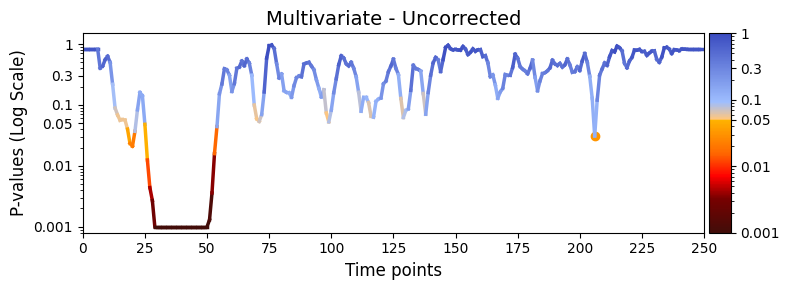

In [7]:
graphics.plot_p_values_over_time(
    result_multivariate_session["pval"],
    title_text="Multivariate - Uncorrected",
    xlabel="Time points",
    num_x_ticks=11
)


**Multiple testing correction**

To reduce the chance of false positives, we apply Benjamini-Hochberg correction to control the false discovery rate:

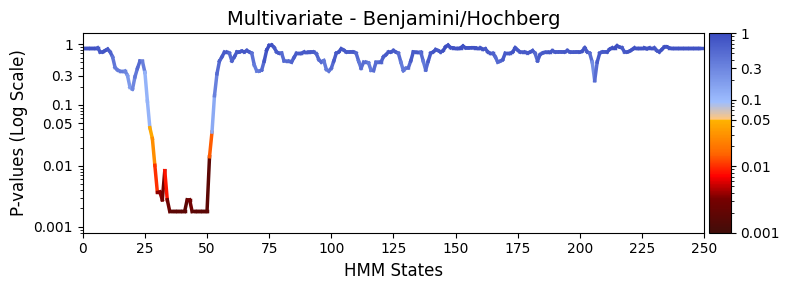

In [8]:
pval_corrected, rejected_corrected =statistics.pval_correction(result_multivariate_session,
                                                               method='fdr_bh')
# Plot p-values
graphics.plot_p_values_over_time(pval_corrected,
                                 title_text ="Multivariate - Benjamini/Hochberg",
                                 xlabel="HMM States",
                                 num_x_ticks=11)

**Cluster-based correction**

To control for family-wise error rate more strictly, we can apply cluster-based permutation testing. This is useful when you expect effects to be temporally contiguous.

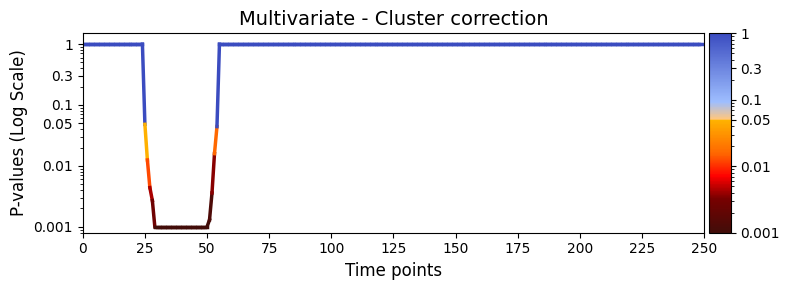

In [9]:
pval_cluster = statistics.pval_cluster_based_correction(result_multivariate_session)

graphics.plot_p_values_over_time(
    pval_cluster,
    title_text="Multivariate - Cluster correction",
    xlabel="Time points",
    num_x_ticks=11
)

# Visualise average probabilities and differences

To help interpret the statistical results from result_multivariate_trials[“pval”], we can compare the average state time courses between the two conditions. This can be done using the function plot_condition_difference, which shows the average probability of each state over time for each condition (0 or 1), along with their difference. We can then highlight time points where the difference is statistically significant based on our multiple testing correction.

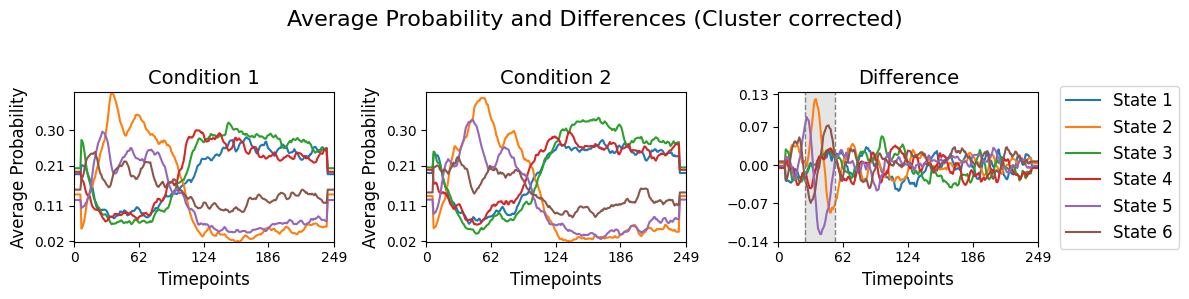

In [10]:
# Detect the intervals of when there is a significant difference, will be highlighed
alpha = 0.05
intervals =statistics.detect_significant_intervals(pval_cluster, alpha)
# Plot the average probability for each state over time for two conditions and their difference.
graphics.plot_condition_difference(Gamma_epoch,
                                   R_trials,
                                   figsize=(12,3),
                                   vertical_lines=intervals,
                                   highlight_boxes=True,
                                   title="Average Probability and Differences (Cluster corrected)",)

# Across-trials testing - Univariate

Now let’s run the univariate test, which looks at each brain state individually. This helps us identify whether a specific state shows a relationship with the stimulus condition (e.g., animate vs inanimate).

This test runs separately for each state and each timepoint, giving a more detailed view of where and when differences occur.

In [17]:
# Set the parameters for between-subject testing
method = "univariate"
Nnull_samples = 10_000 # Number of permutations (default = 1000)
# Perform across-subject testing
result_univariate =statistics.test_across_trials(D_data=Gamma_epoch,
                                                R_data=R_trials,
                                                indices_blocks=idx_trials_session,
                                                method=method,
                                                Nnull_samples=Nnull_samples)

performing permutation testing per timepoint
Total possible permutations: 1.29e+2459
Running number of permutations: 10000


100%|██████████| 250/250 [06:47<00:00,  1.63s/it]


**Visualising univariate results**

We can now plot the p-values as a matrix where each row is a state and each column is a timepoint.
This is done by using the plot_p_value_matrix function from the graphics module. > Lower p-values (below α = 0.05) are shown in warm colours, while higher p-values are shown in cool colours.

In [21]:
result_univariate["pval"].T[0]

array([[0.6996, 0.6996, 0.6996, ..., 0.6996, 0.6996, 0.6996],
       [0.5641, 0.5641, 0.5641, ..., 0.5641, 0.5641, 0.5641],
       [0.7035, 0.7035, 0.7035, ..., 0.7035, 0.7035, 0.7035],
       [0.46  , 0.46  , 0.46  , ..., 0.46  , 0.46  , 0.46  ],
       [0.9357, 0.9357, 0.9357, ..., 0.9357, 0.9357, 0.9357],
       [0.2619, 0.2619, 0.2619, ..., 0.2619, 0.2619, 0.2619]])

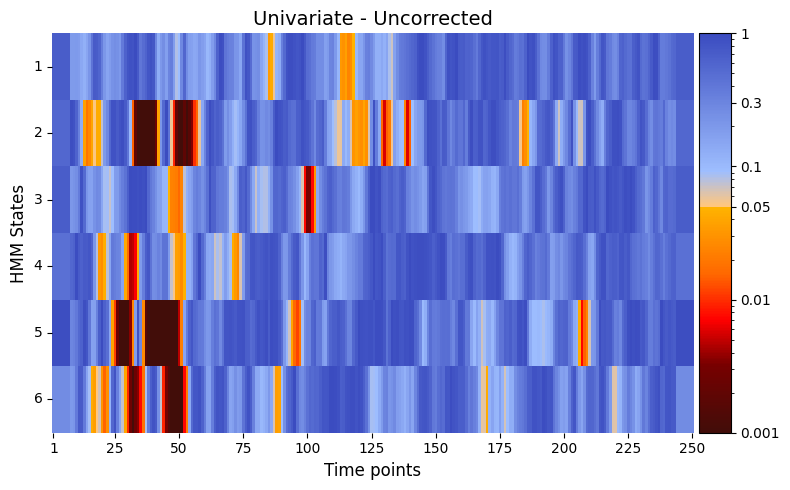

In [22]:
# Plot p-values
# P-values between reaction time and each state as function of time
graphics.plot_p_value_matrix(result_univariate["pval"].T[0],
                             title_text ="Univariate - Uncorrected",
                             figsize=(8, 5),
                             xlabel="Time points",
                             ylabel="HMM States",
                             annot=False,
                             num_x_ticks=11)

**Multiple Comparison**

To be sure there is no type 1 error, we can apply the Benjamini/Hochberg to control the False Discovery Rate

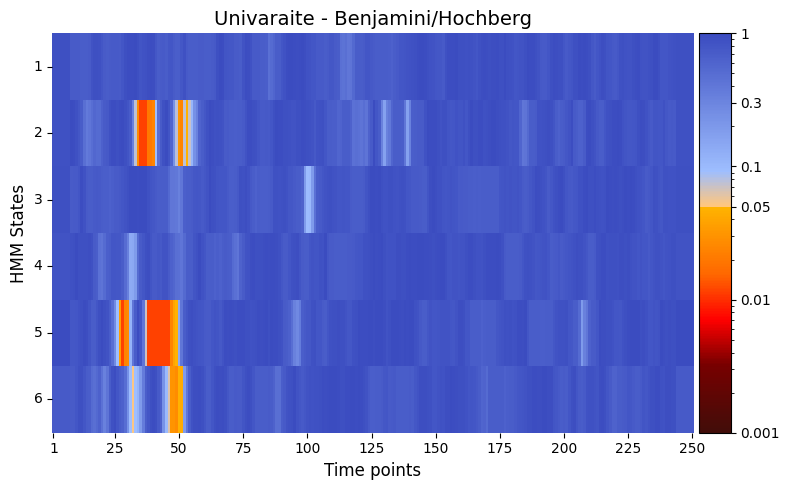

In [23]:
pval_corrected, rejected_corrected =statistics.pval_correction(result_univariate,
                                                               method='fdr_bh')
# Plot p-values
graphics.plot_p_value_matrix(pval_corrected.T[0],
                             title_text ="Univaraite - Benjamini/Hochberg",
                             figsize=(8, 5),
                             xlabel="Time points",
                             ylabel="HMM States",
                             annot=False,
                             num_x_ticks=11)

**Cluster-based correction for univariate test**

We can also apply cluster-based correction here to account for contiguous significant effects across time:

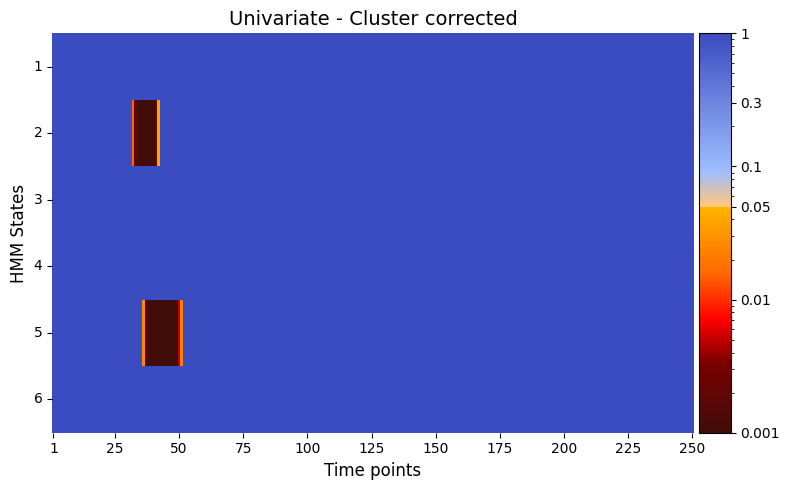

In [24]:
pval_cluster =statistics.pval_cluster_based_correction(result_univariate, individual_feature=True,)
# Plot p-values
graphics.plot_p_value_matrix(pval_cluster.T[0],
                             title_text ="Univariate - Cluster corrected",
                             figsize=(8, 5),
                             xlabel="Time points",
                             ylabel="HMM States",
                             annot=False,
                             num_x_ticks=11)

**Family-Wise Error Rate (FWER) correction**:
Applying FWER correction

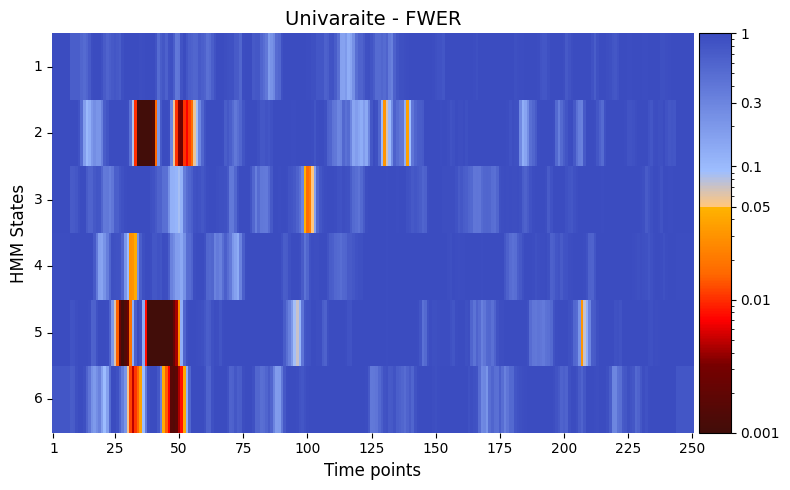

In [25]:
# Correct for FWER
pval_FWER = statistics.pval_FWER_correction(result_univariate)

# Correct p-values using FWER
graphics.plot_p_value_matrix(pval_FWER.T,
                             title_text ="Univaraite - FWER",figsize=(8, 5),
                             xlabel="Time points",
                             ylabel="HMM States",
                             annot=False,
                             num_x_ticks=11)